# Issue #305 — dedicated BEST_FULL keep/skip correction

This notebook tests whether #302's apparent 2023 keep/skip gain survives a
baseline-only head and an exact same-exposure placement null. The independent
unit is an issue; 2024+ is sealed.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'src' / 'issue305').is_dir())
OUTPUT = ROOT / 'results/issue-305'
decision = json.loads((OUTPUT / 'decision.json').read_text())
decision

{'issue': 305,
 'baseline': '#299/#302 exact atomic B0_BEST_FULL',
 'model': 'dedicated expert-label-invariant expanding BEST_FULL keep/skip',
 'decision': {'verdict': 'SHARED_HEAD_EXPOSURE_REDUCTION_ONLY',
  'promotable': False,
  'development_signal_accepted': False,
  'matched_support_issues': 227,
  'prediction_years': [2021, 2022, 2023],
  'sealed_years': '2024+ not read',
  'primary_2023_terminal_capital_cny': 92888.277325,
  'primary_2023_capital_growth_pct': -7.111722674999998,
  'baseline_2023_terminal_capital_cny': 79248.96196799999,
  'baseline_2023_capital_growth_pct': -20.751038032000015,
  'cash_2023_terminal_capital_cny': 100000.0,
  'matched_lift_cny': 13639.315357000014,
  'matched_lift_pp': 13.639315357000015,
  'funded_2023_issues': 8,
  'exact_executed_exposure_percentile': 0.4270622395990452,
  'exact_null_combination_count': 23535820,
  'legacy_302_exact_percentile': 0.785127159368146,
  'all_primary_sensitivity_fits_converged': True,
  'alpha_lift_sign_stable': T

## Capital paths and matched controls

,evaluation_year,condition,funded_issues,terminal_capital_cny,capital_growth_pct,stake_cny,max_drawdown_pct,longest_losing_issue_streak,worst_rolling_10_pnl_cny
0,2021,DEDICATED_MLP,0,100000.000000,0.000000,0.0,0.000000,0,0.000000
1,2022,DEDICATED_MLP,0,100000.000000,0.000000,0.0,0.000000,0,0.000000
2,2023,DEDICATED_MLP,8,92888.277325,-7.111723,34992.0,7.426286,2,-6758.529561
3,2021,DEDICATED_MLP_ALPHA5,4,90873.276422,-9.126724,17496.0,9.126724,2,-3523.526624
4,2022,DEDICATED_MLP_ALPHA5,6,90729.690712,-9.270309,26244.0,9.270309,1,-3613.788296
5,2023,DEDICATED_MLP_ALPHA5,10,97545.313523,-2.454686,43740.0,11.884994,2,-12890.229206
6,2021,DEDICATED_MLP_ALPHA50,0,100000.000000,0.000000,0.0,0.000000,0,0.000000
7,2022,DEDICATED_MLP_ALPHA50,0,100000.000000,0.000000,0.0,0.000000,0,0.000000
8,2023,DEDICATED_MLP_ALPHA50,0,100000.000000,0.000000,0.0,0.000000,0,0.000000
9,2021,ISSUE_BLOCK_SHUFFLED,0,100000.000000,0.000000,0.0,0.000000,0,0.000000


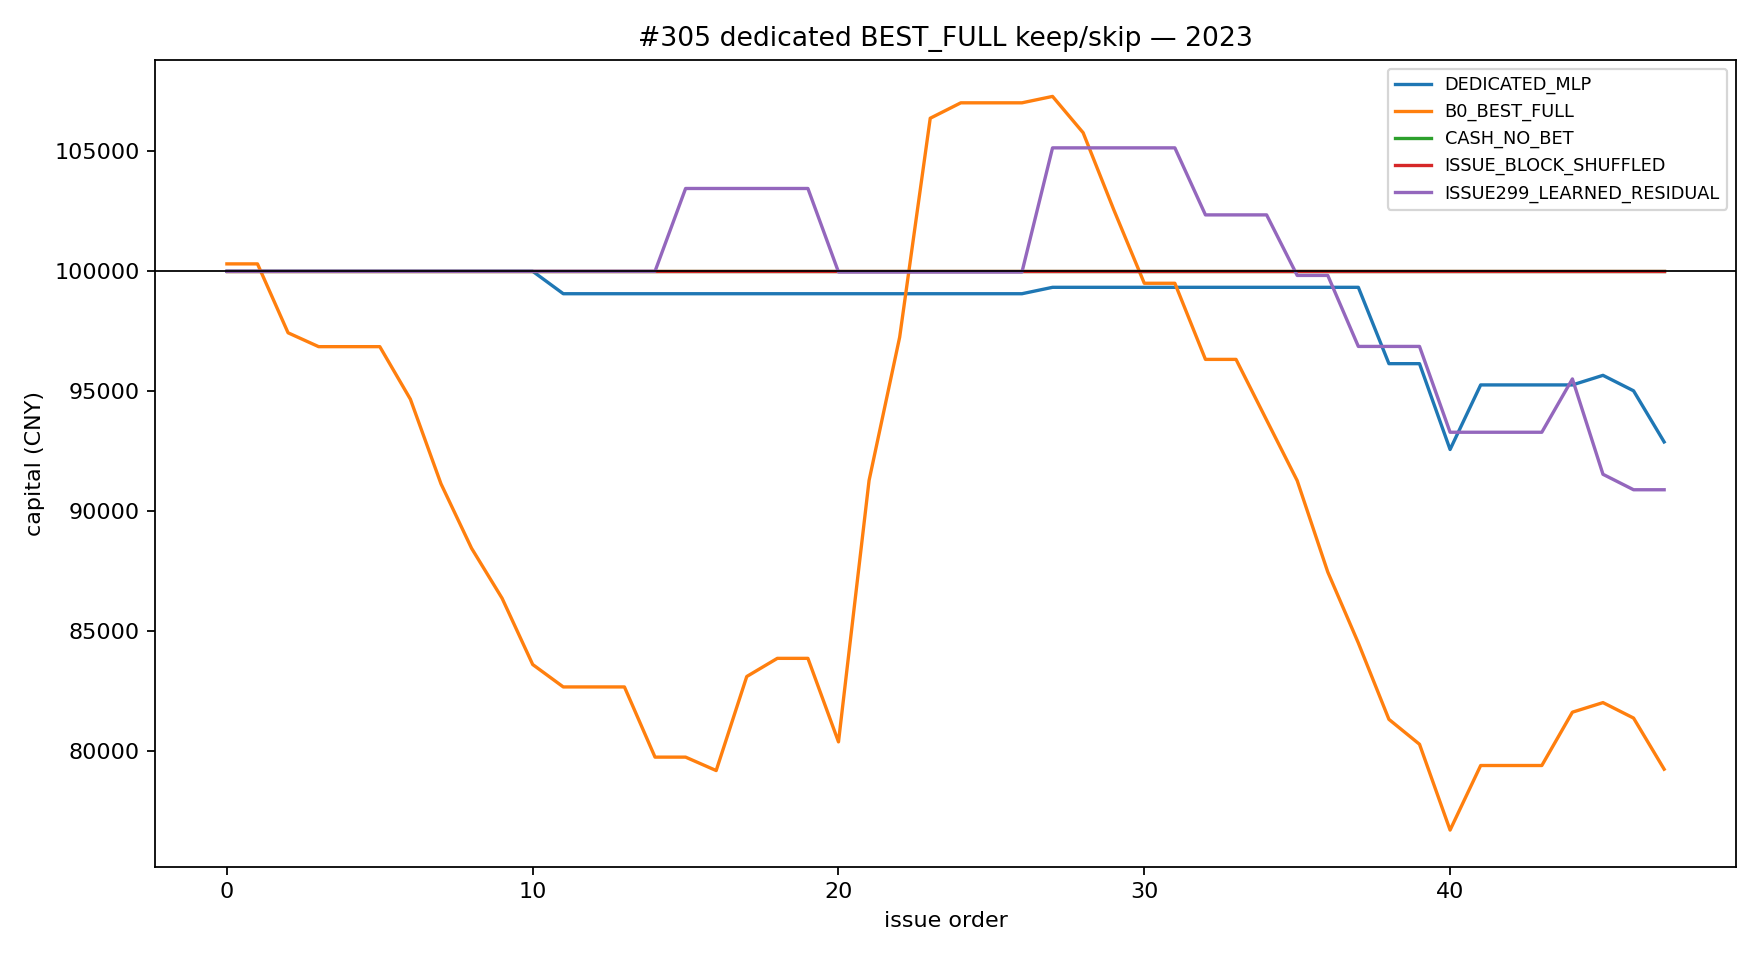

In [2]:
summary = pd.read_csv(OUTPUT / 'policy_summary.csv')
focus = ['DEDICATED_MLP','DEDICATED_MLP_ALPHA5','DEDICATED_MLP_ALPHA50',
         'RIDGE_CONTROL','ISSUE_BLOCK_SHUFFLED','B0_BEST_FULL','CASH_NO_BET',
         'ISSUE299_LEARNED_RESIDUAL','ORACLE_DIAGNOSTIC']
cols = ['evaluation_year','condition','funded_issues','terminal_capital_cny',
        'capital_growth_pct','stake_cny','max_drawdown_pct',
        'longest_losing_issue_streak','worst_rolling_10_pnl_cny']
display(summary[summary.condition.isin(focus)][cols])
display(Image(filename=str(OUTPUT / 'capital_paths_2023.png')))

## Exact executed-exposure null

{'year': 2023,
 'active_destination_issues': 35,
 'funded_count': 8,
 'stake_per_funded_issue_cny': 4374.0,
 'total_stake_cny': 34992.0,
 'combination_count': 23535820,
 'distinct_terminal_values': 3941613,
 'histogram_bins': 254,
 'observed_terminal_capital_cny': 92888.28,
 'exact_percentile': 0.4270622395990452,
 'null_p05_terminal_capital_cny': 82343.06,
 'null_median_terminal_capital_cny': 94602.82,
 'null_p95_terminal_capital_cny': 110709.95,
 'histogram_bin_width_cny': 250.0}

{'year': 2023,
 'active_destination_issues': 35,
 'funded_count': 6,
 'stake_per_funded_issue_cny': 4374.0,
 'total_stake_cny': 26244.0,
 'combination_count': 1623160,
 'distinct_terminal_values': 1219949,
 'histogram_bins': 219,
 'observed_terminal_capital_cny': 102633.14,
 'exact_percentile': 0.785127159368146,
 'null_p05_terminal_capital_cny': 85408.54,
 'null_median_terminal_capital_cny': 95523.05,
 'null_p95_terminal_capital_cny': 110638.43,
 'histogram_bin_width_cny': 250.0}

,bin_lower_cny,bin_upper_cny,multiplicity,bin_midpoint_cny,probability
0,72750.0,73000.0,1,72875.0,4.248843e-08
1,73000.0,73250.0,8,73125.0,3.399074e-07
2,73250.0,73500.0,24,73375.0,1.019722e-06
3,73500.0,73750.0,70,73625.0,2.974190e-06
4,73750.0,74000.0,153,73875.0,6.500730e-06
...,...,...,...,...,...
249,135000.0,135250.0,2,135125.0,8.497686e-08
250,135250.0,135500.0,2,135375.0,8.497686e-08
251,135500.0,135750.0,2,135625.0,8.497686e-08
252,135750.0,136000.0,5,135875.0,2.124421e-07


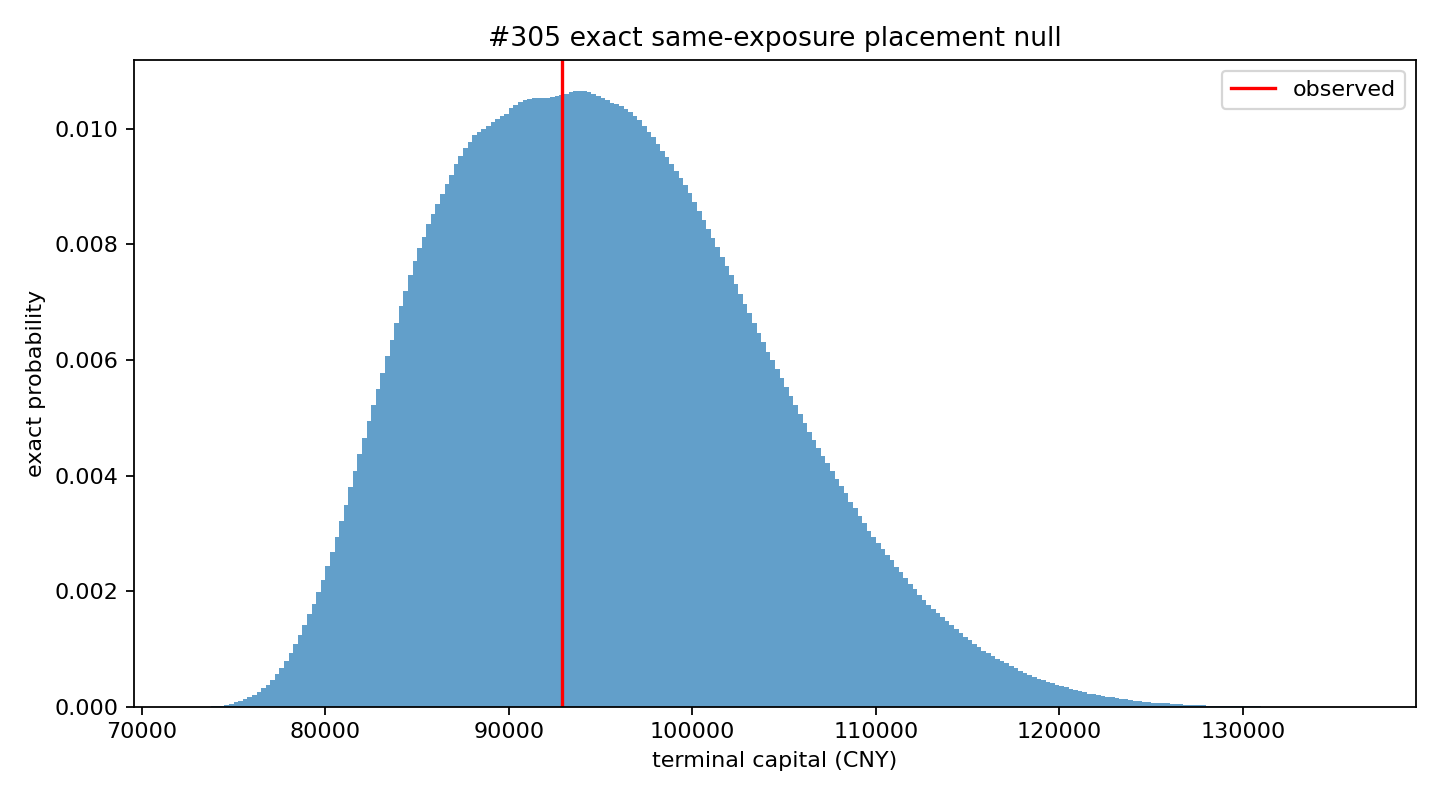

In [3]:
null_receipt = json.loads((OUTPUT / 'exact_exposure_null_2023.json').read_text())
legacy_receipt = json.loads((OUTPUT / 'legacy_302_exact_null.json').read_text())
display(null_receipt)
display(legacy_receipt)
display(pd.read_csv(OUTPUT / 'exact_exposure_null_histogram_2023.csv'))
display(Image(filename=str(OUTPUT / 'exact_exposure_null_2023.png')))

## Convergence and sensitivity

,mean_iterations,downside_iterations
condition,,
DEDICATED_MLP,95,23
DEDICATED_MLP_ALPHA5,256,118
DEDICATED_MLP_ALPHA50,15,16
ISSUE_BLOCK_SHUFFLED,88,29
RIDGE_CONTROL,1,1


,mean_converged,downside_converged
condition,,
DEDICATED_MLP,True,True
DEDICATED_MLP_ALPHA5,True,True
DEDICATED_MLP_ALPHA50,True,True
ISSUE_BLOCK_SHUFFLED,True,True
RIDGE_CONTROL,True,True


,condition,funded_issues,terminal_capital_cny,capital_growth_pct,lift_vs_best_full_cny,max_drawdown_pct,decision_jaccard_vs_primary
0,DEDICATED_MLP,8,92888.277325,-7.111723,13639.315357,7.426286,1.000000
1,DEDICATED_MLP_ALPHA5,10,97545.313523,-2.454686,18296.351555,11.884994,0.500000
2,DEDICATED_MLP_ALPHA50,0,100000.000000,0.000000,20751.038032,0.000000,0.000000
3,RIDGE_CONTROL,11,89622.237309,-10.377763,10373.275341,12.914742,0.727273
4,ISSUE_BLOCK_SHUFFLED,0,100000.000000,0.000000,20751.038032,0.000000,0.000000


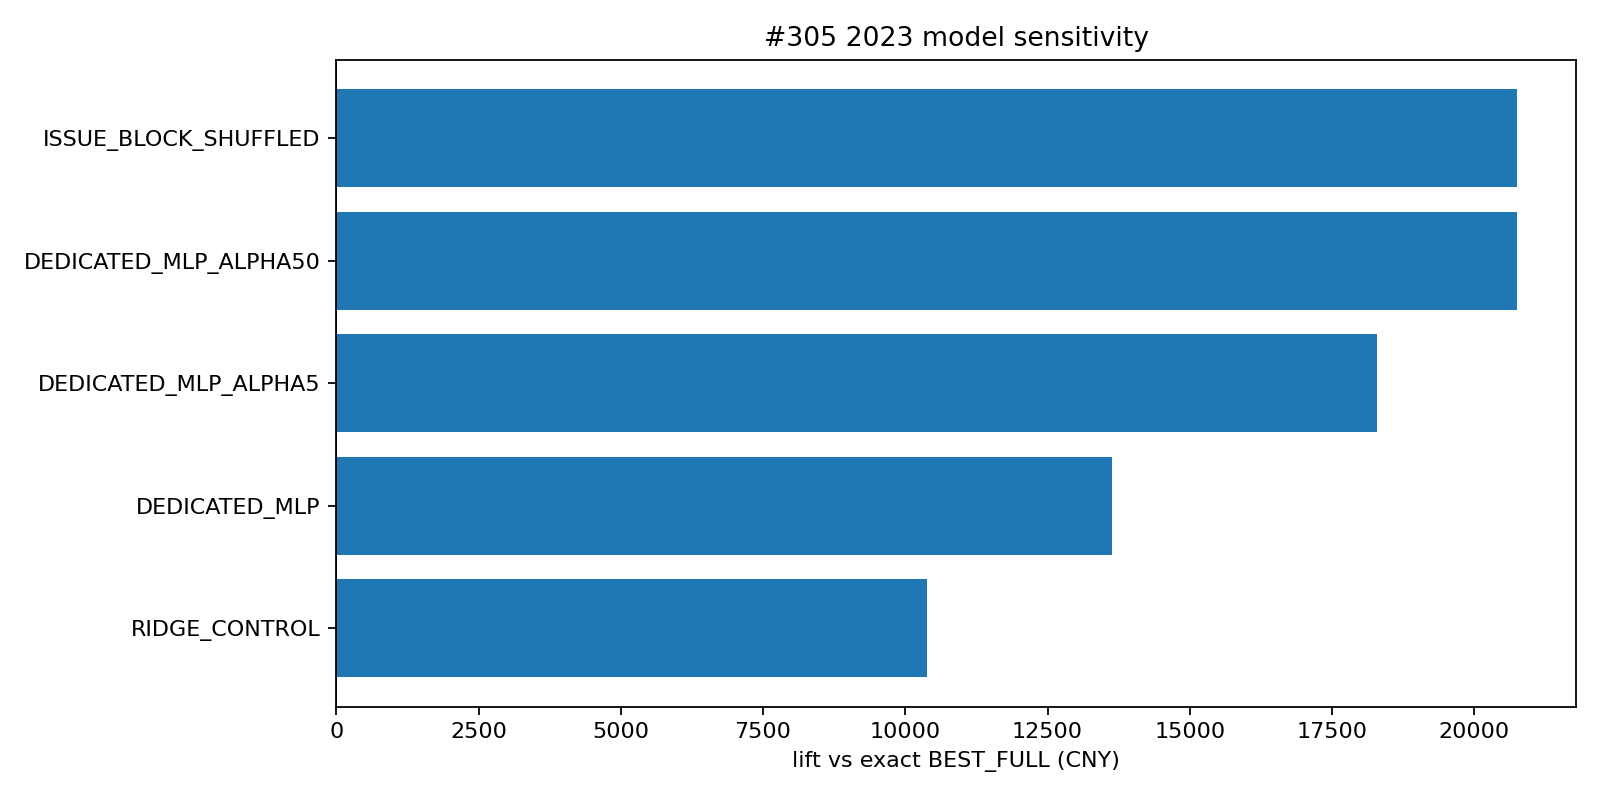

In [4]:
receipts = pd.read_csv(OUTPUT / 'fit_receipts.csv')
display(receipts.groupby('condition')[['mean_iterations','downside_iterations']].max())
display(receipts.groupby('condition')[['mean_converged','downside_converged']].all())
display(pd.read_csv(OUTPUT / 'sensitivity_2023.csv'))
display(Image(filename=str(OUTPUT / 'sensitivity_2023.png')))

## Decision interpretation

The independent model loses 7.11% in 2023 while fixed BEST_FULL loses 20.75%,
but its eight funded issues are only at the 42.71st percentile of all exact
same-count placements. Alpha sensitivity changes the funded set materially and
the shuffled-state control chooses cash. Therefore exposure reduction explains
the lift; dedicated issue-selection skill is not identified. The expert-label
NO_PROMOTION from #302 remains controlling.